# 04 – GNN district scoring

A graph neural network over the district graph (edges = inferred `connectsTo`) receives a user's
preference weights and predicts a match score for every district. It is trained on the exact
score from `kg/scoring.py` for random preferences, so we can measure precisely how well it
learns it – and what goes wrong with a naive architecture.

In [1]:
import sys, warnings, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))  # repository root (notebooks live in kg/notebooks/)
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from scipy.stats import spearmanr

from kg.build_kg import load_kg
from kg import gnn
from kg.config import FEATURES_OUTPUT
from kg.data.district_mapper import load_districts
features = {int(k): v for k, v in json.loads(FEATURES_OUTPUT.read_text(encoding="utf-8")).items()}
districts = load_districts()
g = load_kg()
data = gnn.build_dataset(g, features)
print(f"nodes={data.num_nodes}  features={data.x.size(1)}  directed edges={data.edge_index.size(1)}")
print(f"edge density: {data.edge_index.size(1) / (23 * 22):.0%} of all possible district pairs")

nodes=23  features=40  directed edges=394
edge density: 78% of all possible district pairs


## 1. Over-smoothing: plain GCN vs GCN with skip connections

`connectsTo` links most district pairs, so one GCN layer already averages each node with
almost every other node. A plain two-layer GCN therefore predicts nearly the same score for
every district (the original version of this project produced exact ties). Adding a skip
connection per layer keeps each district's own features.

In [3]:
class PlainGCN(torch.nn.Module):
    def __init__(self, in_dim, hidden=32):
        super().__init__()
        self.conv1 = GCNConv(in_dim + 3, hidden)
        self.conv2 = GCNConv(hidden, 1)
    def forward(self, x, edge_index, pref):
        h = torch.cat([x, pref.unsqueeze(0).expand(x.size(0), -1)], dim=1)
        return torch.sigmoid(self.conv2(F.relu(self.conv1(h, edge_index)), edge_index)).squeeze(-1)

def fit(model, epochs=60):
    torch.manual_seed(0)
    prefs, targets = gnn.generate_labels(features)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    for _ in range(epochs):
        for i in torch.randperm(len(prefs)).tolist():
            loss = F.mse_loss(model(data.x, data.edge_index, prefs[i]), targets[i])
            opt.zero_grad(); loss.backward(); opt.step()
    return model

plain = fit(PlainGCN(data.x.size(1)))
skip = gnn.train(data, features, verbose=False)
comparison = pd.DataFrame({
    "plain GCN": gnn.evaluate(plain, data, features),
    "GCN + skip connections": gnn.evaluate(skip, data, features),
}).T
comparison

,spearman_mean,mae_mean,top3_overlap_mean
plain GCN,0.7081,0.1000,0.4100
GCN + skip connections,0.9954,0.0068,0.9533


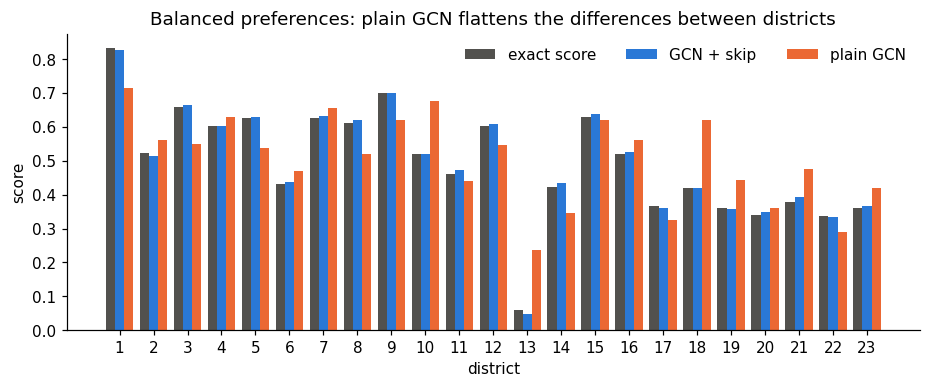

In [4]:
balanced = [1 / 3, 1 / 3, 1 / 3]
exact = gnn.target_scores(features, balanced)
fig, ax = plt.subplots(figsize=(10, 3.5))
x = np.arange(1, 24)
ax.bar(x - 0.27, exact, 0.27, label="exact score", color="#52514e")
ax.bar(x, gnn.predict(skip, data, balanced), 0.27, label="GCN + skip", color="#2a78d6")
ax.bar(x + 0.27, gnn.predict(plain, data, balanced), 0.27, label="plain GCN", color="#eb6834")
ax.set_xticks(x); ax.set_xlabel("district"); ax.set_ylabel("score"); ax.legend(frameon=False, ncol=3)
ax.set_title("Balanced preferences: plain GCN flattens the differences between districts"); plt.show()

## 2. Rankings for example profiles

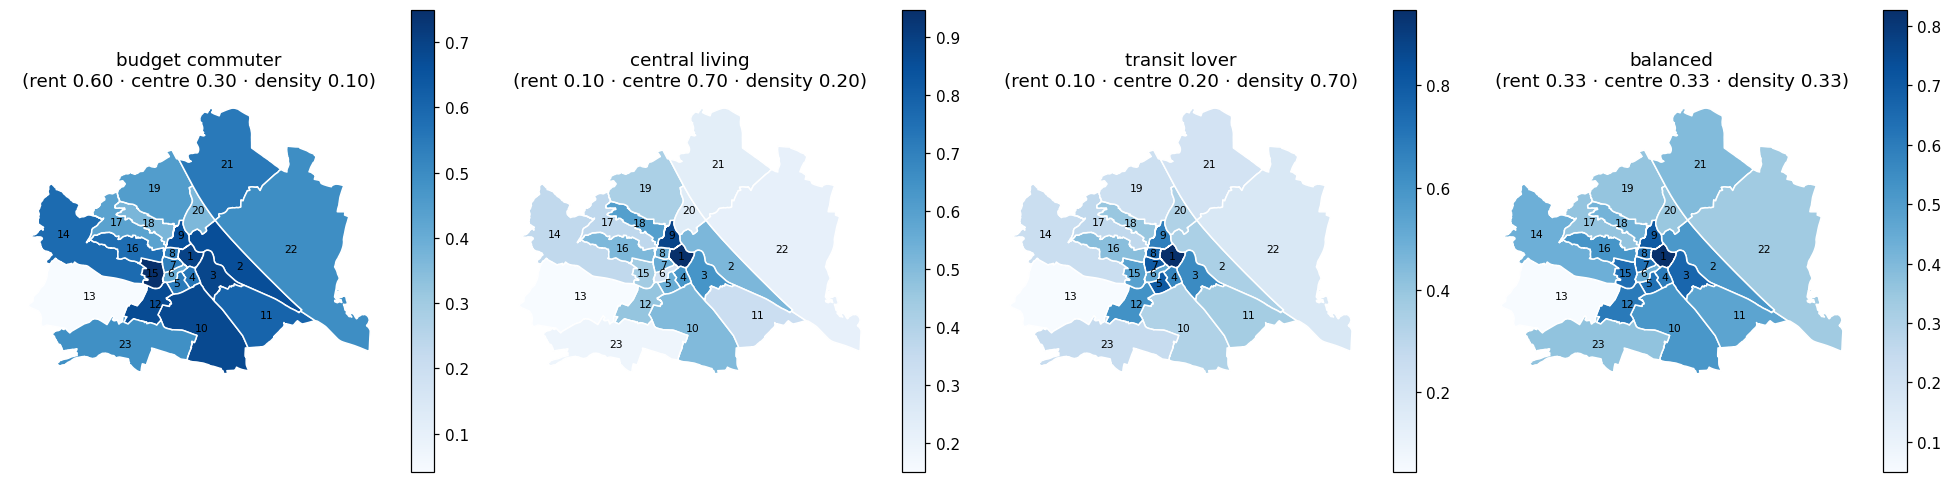

In [5]:
from kg.data.district_mapper import load_districts
def choropleth(ax, values: dict, title: str, cmap="Blues", **kw):
    gdf = districts.assign(value=districts["district"].map(values))
    gdf.plot(column="value", ax=ax, cmap=cmap, edgecolor="white", linewidth=1, legend=True,
             missing_kwds={"color": "#e5e5e5", "hatch": "///", "label": "no data"}, **kw)
    for _, row in gdf.iterrows():
        c = row.geometry.representative_point()
        ax.annotate(str(row.district), (c.x, c.y), ha="center", va="center", fontsize=7)
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, pref) in zip(axes, gnn.PROFILES.items()):
    scores = gnn.predict(skip, data, pref)
    choropleth(ax, {d: float(scores[d - 1]) for d in range(1, 24)},
               f"{name.replace('_', ' ')}\n(rent {pref[0]:.2f} · centre {pref[1]:.2f} · density {pref[2]:.2f})")
plt.tight_layout(); plt.show()

## Take-aways

* With skip connections the GNN reproduces the transparent score almost perfectly on unseen
  preference vectors (see the table above); without them it over-smooths.
* Because the training target *is* the formula, the GNN cannot be better than it – the web app
  therefore uses the exact formula, and the GNN serves as the course's demonstration of message
  passing over the knowledge graph. A natural extension would be training on real user feedback
  (e.g. which districts people actually choose), where the graph structure could add information
  the formula does not have.